In [1]:
# ============================================
# CELL 1: IMPORT LIBRARIES
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import time
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
import joblib
import warnings
warnings.filterwarnings('ignore')

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [2]:
# ============================================
# CELL 2: DOWNLOAD STOPWORDS & SETUP
# ============================================

nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

print("=" * 80)
print("🚀 AI-POWERED PHISHING DETECTION SYSTEM")
print("   Multinomial Naive Bayes Classifier - Single 80/20 Split")
print("   Dataset: phishing_legit_dataset_KD_10000_final.csv")
print("=" * 80)
print("✅ Stopwords downloaded!")

🚀 AI-POWERED PHISHING DETECTION SYSTEM
   Multinomial Naive Bayes Classifier - Single 80/20 Split
   Dataset: phishing_legit_dataset_KD_10000_final.csv
✅ Stopwords downloaded!


In [3]:
# ============================================
# CELL 3: LOAD DATASET (FINAL VERSION)
# ============================================

print("\n📂 LOADING DATASET...")
df = pd.read_csv('phishing_legit_dataset_KD_10000_final.csv')

print("\n" + "=" * 80)
print("📊 DATASET INFO")
print("=" * 80)
print(f"Total samples: {len(df)}")
print(f"Phishing (1): {df['label'].sum()}")
print(f"Legitimate (0): {len(df) - df['label'].sum()}")

print(f"\n📊 Class Distribution:")
print(f"   Legitimate: {len(df) - df['label'].sum()} ({((len(df) - df['label'].sum()) / len(df)) * 100:.1f}%)")
print(f"   Phishing:   {df['label'].sum()} {(df['label'].sum() / len(df)) * 100:.1f}%)")

print(f"\n📊 Columns: {df.columns.tolist()}")

if 'severity' in df.columns:
    print("\n📊 Severity Distribution:")
    print(df['severity'].value_counts())

df.head()


📂 LOADING DATASET...

📊 DATASET INFO
Total samples: 10000
Phishing (1): 5630
Legitimate (0): 4370

📊 Class Distribution:
   Legitimate: 4370 (43.7%)
   Phishing:   5630 56.3%)

📊 Columns: ['text', 'label', 'phishing_type', 'severity', 'confidence']

📊 Severity Distribution:
severity
high      4488
low       4245
medium    1267
Name: count, dtype: int64


,text,label,phishing_type,severity,confidence
0,Subject: Office maintenance\n\nThanks for your...,0,legitimate,low,0.95
1,"Hello, your profile has been locked. Use the s...",1,credential_harvesting,high,0.89
2,"Hi there, congratulations! You are the winner ...",0,financial_scam,medium,0.69
3,"Attention, this is the fraud prevention accoun...",0,authority_scam,high,0.91
4,"Notice, your profile has been restricted. Use ...",1,credential_harvesting,high,0.80


In [4]:
# ============================================
# CELL 4: TEXT PREPROCESSING (NLP PIPELINE)
# ============================================

print("\n" + "=" * 80)
print("🔧 TEXT PREPROCESSING (NLP PIPELINE)")
print("=" * 80)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return ' '.join(words)

df['cleaned_text'] = df['text'].apply(clean_text)

print("✅ Text preprocessing complete!")
print(f"\n📝 Sample Original (first 100 chars):")
print(f"   {df['text'].iloc[0][:100]}...")
print(f"\n📝 Sample Cleaned (first 100 chars):")
print(f"   {df['cleaned_text'].iloc[0][:100]}...")

df[['text', 'cleaned_text']].head()


🔧 TEXT PREPROCESSING (NLP PIPELINE)
✅ Text preprocessing complete!

📝 Sample Original (first 100 chars):
   Subject: Office maintenance

Thanks for your help on the analysis. I've pushed the changes and left ...

📝 Sample Cleaned (first 100 chars):
   subject office maintenance thanks help analysis ive pushed changes left comments pr clarity let know...


,text,cleaned_text
0,Subject: Office maintenance\n\nThanks for your...,subject office maintenance thanks help analysi...
1,"Hello, your profile has been locked. Use the s...",hello profile locked use secure link verify us...
2,"Hi there, congratulations! You are the winner ...",hi congratulations winner refund collect gift ...
3,"Attention, this is the fraud prevention accoun...",attention fraud prevention accounts team secur...
4,"Notice, your profile has been restricted. Use ...",notice profile restricted use secure link rese...


In [5]:
# ============================================
# CELL 5: TF-IDF FEATURE EXTRACTION
# ============================================

print("\n" + "=" * 80)
print("📝 TF-IDF FEATURE EXTRACTION")
print("=" * 80)

vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X = vectorizer.fit_transform(df['cleaned_text'])
y = df['label']

print(f"✅ Features shape: {X.shape} (10,000 emails x {X.shape[1]} features)")


📝 TF-IDF FEATURE EXTRACTION
✅ Features shape: (10000, 573) (10,000 emails x 573 features)


In [6]:
# ============================================
# CELL 6: SEPARATE PHISHING AND LEGITIMATE EMAILS
# ============================================

print("\n" + "=" * 80)
print("📊 SEPARATING PHISHING AND LEGITIMATE EMAILS")
print("=" * 80)

# Convert y to numpy array
y_numpy = y.to_numpy() if hasattr(y, 'to_numpy') else np.array(y)

# Get indices
phishing_indices = np.where(y_numpy == 1)[0]
legit_indices = np.where(y_numpy == 0)[0]

# Extract
phishing_X = X[phishing_indices]
legit_X = X[legit_indices]
phishing_y = y_numpy[phishing_indices]
legit_y = y_numpy[legit_indices]

print(f"Phishing emails: {phishing_X.shape[0]}")
print(f"Legitimate emails: {legit_X.shape[0]}")
print(f"Total: {phishing_X.shape[0] + legit_X.shape[0]}")


📊 SEPARATING PHISHING AND LEGITIMATE EMAILS
Phishing emails: 5630
Legitimate emails: 4370
Total: 10000


In [7]:
# ============================================
# CELL 7: SPLIT PHISHING AND LEGITIMATE SEPARATELY (80/20)
# ============================================

print("\n" + "=" * 80)
print("📊 SPLITTING PHISHING AND LEGITIMATE SEPARATELY")
print("=" * 80)
print("Phishing: 80% Train, 20% Validation")
print("Legitimate: 80% Train, 20% Validation")

# Split phishing: 80% training, 20% validation
X_phish_train, X_phish_val, y_phish_train, y_phish_val = train_test_split(
    phishing_X, phishing_y, test_size=0.2, random_state=42
)

# Split legitimate: 80% training, 20% validation
X_legit_train, X_legit_val, y_legit_train, y_legit_val = train_test_split(
    legit_X, legit_y, test_size=0.2, random_state=42
)

print(f"\n📊 Phishing:")
print(f"   Training: {X_phish_train.shape[0]} (80%)")
print(f"   Validation: {X_phish_val.shape[0]} (20%)")

print(f"\n📊 Legitimate:")
print(f"   Training: {X_legit_train.shape[0]} (80%)")
print(f"   Validation: {X_legit_val.shape[0]} (20%)")


📊 SPLITTING PHISHING AND LEGITIMATE SEPARATELY
Phishing: 80% Train, 20% Validation
Legitimate: 80% Train, 20% Validation

📊 Phishing:
   Training: 4504 (80%)
   Validation: 1126 (20%)

📊 Legitimate:
   Training: 3496 (80%)
   Validation: 874 (20%)


In [8]:
# ============================================
# CELL 8: COMBINE TRAINING AND VALIDATION SETS
# ============================================

print("\n" + "=" * 80)
print("📊 COMBINING TRAINING AND VALIDATION SETS")
print("=" * 80)

# Combine training sets
X_train = np.vstack([X_phish_train.toarray(), X_legit_train.toarray()])
y_train = np.concatenate([y_phish_train, y_legit_train])

# Combine validation sets
X_val = np.vstack([X_phish_val.toarray(), X_legit_val.toarray()])
y_val = np.concatenate([y_phish_val, y_legit_val])

# Shuffle training set
train_indices = np.random.permutation(len(y_train))
X_train = X_train[train_indices]
y_train = y_train[train_indices]

# Shuffle validation set
val_indices = np.random.permutation(len(y_val))
X_val = X_val[val_indices]
y_val = y_val[val_indices]

print(f"\n📊 Training Set ({len(X_train)} samples):")
train_legit = (y_train == 0).sum()
train_phish = (y_train == 1).sum()
print(f"   Legitimate: {train_legit} ({train_legit/len(X_train)*100:.1f}%)")
print(f"   Phishing:   {train_phish} ({train_phish/len(X_train)*100:.1f}%)")

print(f"\n📊 Validation Set ({len(X_val)} samples):")
val_legit = (y_val == 0).sum()
val_phish = (y_val == 1).sum()
print(f"   Legitimate: {val_legit} ({val_legit/len(X_val)*100:.1f}%)")
print(f"   Phishing:   {val_phish} ({val_phish/len(X_val)*100:.1f}%)")


📊 COMBINING TRAINING AND VALIDATION SETS

📊 Training Set (8000 samples):
   Legitimate: 3496 (43.7%)
   Phishing:   4504 (56.3%)

📊 Validation Set (2000 samples):
   Legitimate: 874 (43.7%)
   Phishing:   1126 (56.3%)


In [9]:
# ============================================
# CELL 9: CHECK FOR CROSS-SET DUPLICATES
# ============================================

print("\n" + "=" * 80)
print("CHECKING FOR CROSS-SET DUPLICATES")
print("=" * 80)

# Convert to DataFrame for comparison
train_df = pd.DataFrame(X_train)
val_df = pd.DataFrame(X_val)

# Check for duplicates
duplicates = pd.merge(train_df, val_df, how='inner').shape[0]

print(f"Training set rows: {len(X_train)}")
print(f"Validation set rows: {len(X_val)}")
print(f"Duplicate rows between train and validation: {duplicates}")

if duplicates == 0:
    print("No cross-set duplicates detected")
else:
    print("Duplicates detected between training and validation sets")



CHECKING FOR CROSS-SET DUPLICATES
Training set rows: 8000
Validation set rows: 2000
Duplicate rows between train and validation: 11
Duplicates detected between training and validation sets


In [10]:
# ============================================
# CELL 10: TRAIN MULTINOMIAL NAIVE BAYES (WITH TIME)
# ============================================

print("\n" + "=" * 80)
print("TRAINING MULTINOMIAL NAIVE BAYES CLASSIFIER")
print("=" * 80)

nb_params = {
    'alpha': 1.0
}

print("Parameters:")
for key, value in nb_params.items():
    print(f"   - {key}: {value}")

start_time = time.time()

model = MultinomialNB(**nb_params)
model.fit(X_train, y_train)

training_time = time.time() - start_time

print("\nTraining complete!")
print(f"Training time: {training_time:.2f} seconds")



TRAINING MULTINOMIAL NAIVE BAYES CLASSIFIER
Parameters:
   - alpha: 1.0

Training complete!
Training time: 0.01 seconds


In [11]:
# ============================================
# CELL 11: MODEL EVALUATION
# ============================================

print("\n" + "=" * 80)
print("📊 MODEL EVALUATION")
print("=" * 80)

# Training accuracy
y_train_pred = model.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred)

# Validation accuracy
y_val_pred = model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_val_pred)

print(f"✅ Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"✅ Validation Accuracy: {val_accuracy * 100:.2f}%")


📊 MODEL EVALUATION
✅ Training Accuracy: 83.08%
✅ Validation Accuracy: 82.70%


In [12]:
# ============================================
# CELL 12: CLASSIFICATION REPORT
# ============================================

print("\n" + "=" * 80)
print("📊 CLASSIFICATION REPORT (Validation Set)")
print("=" * 80)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, target_names=['Legitimate', 'Phishing']))

# Extract metrics
precision = precision_score(y_val, y_val_pred)
recall = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)

print("\n📊 Metrics Summary:")
print(f"   Precision (Phishing): {precision:.4f}")
print(f"   Recall (Phishing):    {recall:.4f}")
print(f"   F1-Score (Phishing):  {f1:.4f}")


📊 CLASSIFICATION REPORT (Validation Set)

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.83      0.76      0.79       874
    Phishing       0.82      0.88      0.85      1126

    accuracy                           0.83      2000
   macro avg       0.83      0.82      0.82      2000
weighted avg       0.83      0.83      0.83      2000


📊 Metrics Summary:
   Precision (Phishing): 0.8228
   Recall (Phishing):    0.8828
   F1-Score (Phishing):  0.8518



📊 CONFUSION MATRIX
   ┌──────────────────────────────────────────────────┐
   │                         Predicted                │
   │                  Legitimate      Phishing        │
   │  Legitimate               660           214 │
   │  Phishing                 132           994 │
   └──────────────────────────────────────────────────┘

📊 Prediction Summary:
   Total validation samples: 2000
   Predicted Phishing:       1208
   Predicted Legitimate:     792


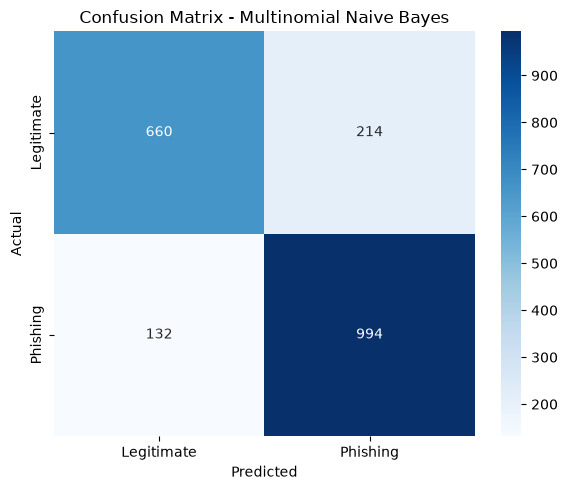

In [13]:
# ============================================
# CELL 13: CONFUSION MATRIX
# ============================================

print("\n" + "=" * 80)
print("📊 CONFUSION MATRIX")
print("=" * 80)

cm = confusion_matrix(y_val, y_val_pred)

print(f"   ┌──────────────────────────────────────────────────┐")
print(f"   │                         Predicted                │")
print(f"   │                  Legitimate      Phishing        │")
print(f"   │  Legitimate      {cm[0][0]:>12}    {cm[0][1]:>10} │")
print(f"   │  Phishing        {cm[1][0]:>12}    {cm[1][1]:>10} │")
print(f"   └──────────────────────────────────────────────────┘")

# Prediction summary
phish_pred = (y_val_pred == 1).sum()
legit_pred = (y_val_pred == 0).sum()

print(f"\n📊 Prediction Summary:")
print(f"   Total validation samples: {len(y_val)}")
print(f"   Predicted Phishing:       {phish_pred}")
print(f"   Predicted Legitimate:     {legit_pred}")

# Visualization
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate', 'Phishing'],
            yticklabels=['Legitimate', 'Phishing'])
plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('confusion_matrix_mnb.png')
plt.show()


TOP FEATURES ASSOCIATED WITH EACH CLASS

Top 15 Features Associated with Legitimate Emails


Rank,Feature,Log Probability
1,best,-3.9137
2,subject,-3.9137
3,draft,-4.3327
4,thanks,-4.3840
5,feedback,-4.4077
6,notes,-4.5228
7,slides,-4.5894
8,know,-4.6229
9,let,-4.6229
10,add,-4.6606



Top 15 Features Associated with Phishing Emails


Rank,Feature,Log Probability
1,account,-3.9860
2,keywords,-4.4841
3,access,-4.5168
4,verification,-4.5709
5,security,-4.6362
6,soon,-4.6473
7,notice,-4.6637
8,dear,-4.7856
9,team,-4.8013
10,link,-4.8496


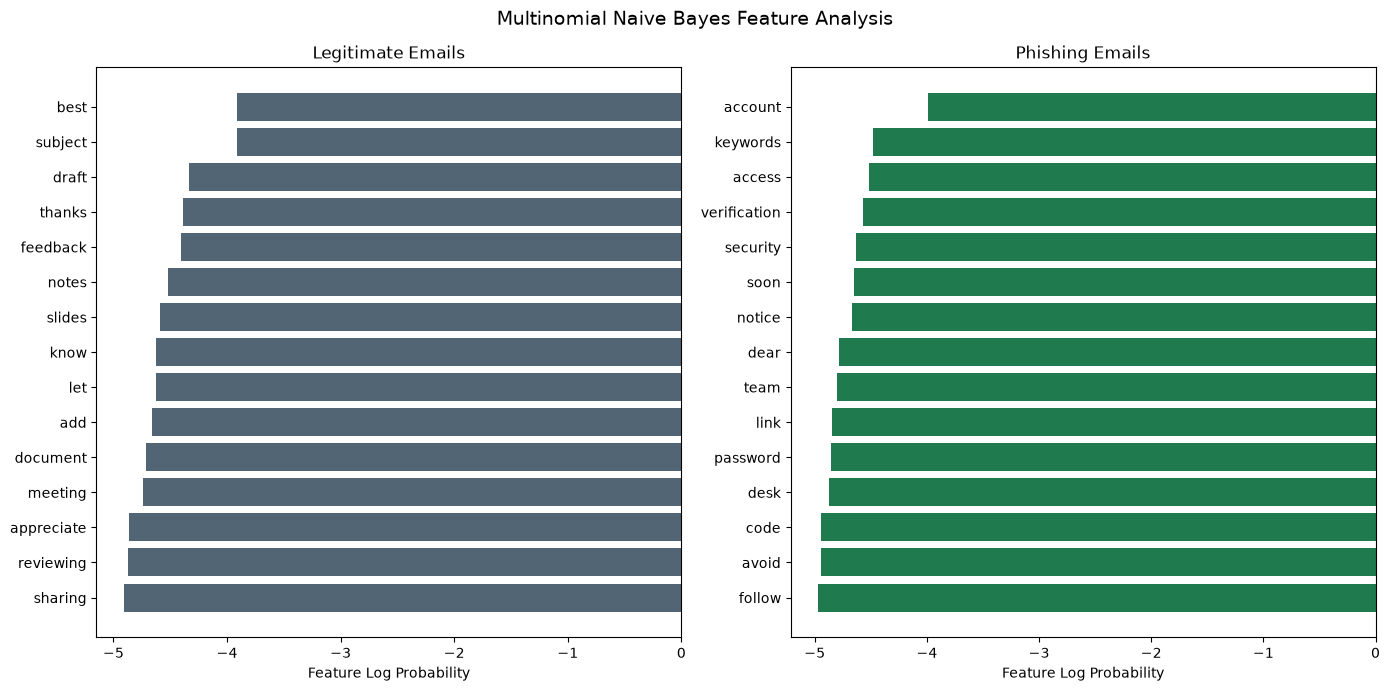

In [14]:
# ============================================
# CELL 14: MULTINOMIAL NAIVE BAYES FEATURE ANALYSIS
# ============================================

print("\n" + "=" * 80)
print("TOP FEATURES ASSOCIATED WITH EACH CLASS")
print("=" * 80)

feature_names = vectorizer.get_feature_names_out()
class_to_row = {class_label: row for row, class_label in enumerate(model.classes_)}

if 0 not in class_to_row or 1 not in class_to_row:
    raise ValueError(f"Expected classes 0 and 1, but model learned {model.classes_.tolist()}")

top_n = 15
legitimate_row = class_to_row[0]
phishing_row = class_to_row[1]
legitimate_idx = np.argsort(model.feature_log_prob_[legitimate_row])[::-1][:top_n]
phishing_idx = np.argsort(model.feature_log_prob_[phishing_row])[::-1][:top_n]

legitimate_features = pd.DataFrame({
    'Rank': np.arange(1, top_n + 1),
    'Feature': feature_names[legitimate_idx],
    'Log Probability': model.feature_log_prob_[legitimate_row, legitimate_idx]
})
phishing_features = pd.DataFrame({
    'Rank': np.arange(1, top_n + 1),
    'Feature': feature_names[phishing_idx],
    'Log Probability': model.feature_log_prob_[phishing_row, phishing_idx]
})

print("\nTop 15 Features Associated with Legitimate Emails")
display(legitimate_features.style.hide(axis='index').format({'Log Probability': '{:.4f}'}))
print("\nTop 15 Features Associated with Phishing Emails")
display(phishing_features.style.hide(axis='index').format({'Log Probability': '{:.4f}'}))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].barh(legitimate_features['Feature'][::-1], legitimate_features['Log Probability'][::-1], color='#526574')
axes[0].set_title('Legitimate Emails')
axes[0].set_xlabel('Feature Log Probability')
axes[1].barh(phishing_features['Feature'][::-1], phishing_features['Log Probability'][::-1], color='#1f7a4d')
axes[1].set_title('Phishing Emails')
axes[1].set_xlabel('Feature Log Probability')
fig.suptitle('Multinomial Naive Bayes Feature Analysis', fontsize=14)
plt.tight_layout()
plt.savefig('feature_analysis_mnb.png', dpi=300, bbox_inches='tight')
plt.show()


In [15]:
# ============================================
# CELL 15: VALIDATION SUMMARY
# ============================================

print("\n" + "=" * 80)
print("VALIDATION SUMMARY")
print("=" * 80)

print(f"Algorithm:                    Multinomial Naive Bayes")
print(f"Total Dataset:                {len(df):,} samples")
print(f"Class Distribution:           Legitimate: {len(df) - int(df['label'].sum()):,}, Phishing: {int(df['label'].sum()):,}")
print(f"Splitting Method:             Separate 80/20 split per class")
print(f"Training Set:                 {len(X_train):,} samples (80%)")
print(f"Validation Set:               {len(X_val):,} samples (20%)")
print(f"Training Accuracy:            {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy:          {val_accuracy * 100:.2f}%")
print(f"Precision (Phishing):         {precision:.4f}")
print(f"Recall (Phishing):            {recall:.4f}")
print(f"F1-Score (Phishing):          {f1:.4f}")
print(f"Training Time:                {training_time:.2f} seconds")
leakage_status = ('No cross-set duplicates detected' if duplicates == 0
                  else 'Duplicates detected between training and validation sets')
print(f"Data Leakage Check:           {leakage_status}")

print("\nMultinomial Naive Bayes Parameters:")
for key, value in nb_params.items():
    print(f"   - {key}: {value}")

print("\nModel is VALID and READY!")



VALIDATION SUMMARY
Algorithm:                    Multinomial Naive Bayes
Total Dataset:                10,000 samples
Class Distribution:           Legitimate: 4,370, Phishing: 5,630
Splitting Method:             Separate 80/20 split per class
Training Set:                 8,000 samples (80%)
Validation Set:               2,000 samples (20%)
Training Accuracy:            83.08%
Validation Accuracy:          82.70%
Precision (Phishing):         0.8228
Recall (Phishing):            0.8828
F1-Score (Phishing):          0.8518
Training Time:                0.01 seconds
Data Leakage Check:           Duplicates detected between training and validation sets

Multinomial Naive Bayes Parameters:
   - alpha: 1.0

Model is VALID and READY!


In [16]:
# CHAPTER 4: RESULTS AND EVALUATION
# Multinomial Naive Bayes Phishing Email Classification
# SECTION A: COMBINED 20-SAMPLE EVALUATION DISPLAY
from IPython.display import HTML, display
import numpy as np
import pandas as pd
from html import escape

# Use the same 20 validation observations for both the table and sample matrix.
sample_size = 20
y_sample_true = np.asarray(y_val).reshape(-1)[:sample_size]
y_sample_pred = np.asarray(y_val_pred).reshape(-1)[:sample_size]

if len(y_sample_true) != sample_size or len(y_sample_pred) != sample_size:
    raise ValueError("The validation set must contain at least 20 observations.")

sample_evaluation = pd.DataFrame({
    "#": np.arange(1, sample_size + 1),
    "Email ID": [f"E{i:03d}" for i in range(1, sample_size + 1)],
    "Ground Truth": np.where(y_sample_true == 1, "Phishing", "Legitimate"),
    "Predicted": np.where(y_sample_pred == 1, "Phishing", "Legitimate")
})

def classify_outcome(actual, predicted):
    outcome_map = {
        ("Phishing", "Phishing"): "TP",
        ("Legitimate", "Legitimate"): "TN",
        ("Legitimate", "Phishing"): "FP",
        ("Phishing", "Legitimate"): "FN"
    }
    return outcome_map[(actual, predicted)]

sample_evaluation["Result"] = [
    classify_outcome(actual, predicted)
    for actual, predicted in zip(
        sample_evaluation["Ground Truth"], sample_evaluation["Predicted"]
    )
]

sample_counts = sample_evaluation["Result"].value_counts()
sample_tp = int(sample_counts.get("TP", 0))
sample_tn = int(sample_counts.get("TN", 0))
sample_fp = int(sample_counts.get("FP", 0))
sample_fn = int(sample_counts.get("FN", 0))
sample_total = sample_tp + sample_tn + sample_fp + sample_fn

def safe_divide(numerator, denominator):
    return numerator / denominator if denominator else 0.0

sample_accuracy = safe_divide(sample_tp + sample_tn, sample_total)
sample_precision = safe_divide(sample_tp, sample_tp + sample_fp)
sample_recall = safe_divide(sample_tp, sample_tp + sample_fn)
sample_specificity = safe_divide(sample_tn, sample_tn + sample_fp)
sample_f1 = safe_divide(
    2 * sample_precision * sample_recall, sample_precision + sample_recall
)

category_ids = {
    label: sample_evaluation.loc[sample_evaluation["Result"] == label, "Email ID"].tolist()
    for label in ("TP", "TN", "FP", "FN")
}

def email_id_text(label):
    values = category_ids[label]
    return ", ".join(values) if values else "None"

result_colours = {"TP": "#1f7a4d", "TN": "#526574", "FP": "#c4322b", "FN": "#d97706"}
table_rows = []
for row in sample_evaluation.itertuples(index=False, name=None):
    number, email_id, ground_truth, predicted, result = row
    truth_class = "phishing-label" if ground_truth == "Phishing" else "legitimate-label"
    pred_class = "phishing-label" if predicted == "Phishing" else "legitimate-label"
    table_rows.append(
        f"<tr><td>{number}</td><td>{escape(email_id)}</td>"
        f"<td><span class='{truth_class}'>{escape(ground_truth)}</span></td>"
        f"<td><span class='{pred_class}'>{escape(predicted)}</span></td>"
        f"<td><strong style='color:{result_colours[result]}'>{result}</strong></td></tr>"
    )

matrix_cells = {
    "TP": (sample_tp, "True Positive", "Phishing → Phishing"),
    "FN": (sample_fn, "False Negative", "Phishing → Legitimate"),
    "FP": (sample_fp, "False Positive", "Legitimate → Phishing"),
    "TN": (sample_tn, "True Negative", "Legitimate → Legitimate")
}

def matrix_cell(label):
    count, name, mapping = matrix_cells[label]
    return (
        f"<div class='matrix-cell cell-{label.lower()}'>"
        f"<div class='matrix-code'>{label}</div><div class='matrix-count'>{count}</div>"
        f"<div class='matrix-name'>{name}</div><div class='matrix-map'>{mapping}</div>"
        f"<div class='matrix-ids'>{escape(email_id_text(label))}</div></div>"
    )

metric_cards = [
    ("Accuracy", sample_accuracy, f"({sample_tp} + {sample_tn}) / {sample_total}"),
    ("Precision", sample_precision, f"{sample_tp} / ({sample_tp} + {sample_fp})"),
    ("Recall (Sensitivity)", sample_recall, f"{sample_tp} / ({sample_tp} + {sample_fn})"),
    ("Specificity", sample_specificity, f"{sample_tn} / ({sample_tn} + {sample_fp})"),
    ("F1-Score", sample_f1,
     f"2 × ({sample_precision:.3f} × {sample_recall:.3f}) / "
     f"({sample_precision:.3f} + {sample_recall:.3f})")
]
metric_html = "".join(
    f"<div class='metric-card'><div class='metric-name'>{escape(name)}</div>"
    f"<div class='metric-value'>{value:.1%}</div>"
    f"<div class='metric-formula'>{escape(formula)}</div></div>"
    for name, value, formula in metric_cards
)

combined_html = f"""
<style>
.ml-evaluation {{font-family:Arial,Helvetica,sans-serif;color:#1f2937;background:#f7f9fc;
  border:1px solid #d9e0e8;border-radius:12px;padding:20px;max-width:1250px;}}
.ml-evaluation * {{box-sizing:border-box;}}
.evaluation-grid {{display:grid;grid-template-columns:minmax(470px,1.08fr) minmax(440px,0.92fr);gap:20px;align-items:start;}}
.panel {{background:#fff;border:1px solid #d9e0e8;border-radius:10px;padding:15px;box-shadow:0 2px 7px rgba(16,24,40,.05);}}
.panel-title {{font-size:17px;font-weight:700;color:#17365d;margin:0 0 10px;}}
.table-scroll {{max-height:560px;overflow:auto;border:1px solid #d9e0e8;border-radius:7px;}}
.sample-table {{width:100%;border-collapse:collapse;font-size:12px;}}
.sample-table th {{position:sticky;top:0;z-index:2;background:#17365d;color:#fff;padding:9px 7px;text-align:center;}}
.sample-table td {{padding:7px;border-bottom:1px solid #e4e9ef;text-align:center;white-space:nowrap;}}
.sample-table tr:nth-child(even) {{background:#f7f9fc;}}
.phishing-label,.legitimate-label {{display:inline-block;padding:3px 7px;border-radius:12px;font-weight:600;}}
.phishing-label {{background:#fde8e7;color:#a51d18;}}
.legitimate-label {{background:#dff5ee;color:#176b5b;}}
.axis-title {{font-size:11px;font-weight:700;letter-spacing:.08em;color:#667085;text-align:center;margin:3px 0 6px;}}
.matrix-columns {{display:grid;grid-template-columns:84px 1fr 1fr;gap:8px;margin-bottom:8px;font-size:12px;font-weight:700;text-align:center;}}
.matrix-grid {{display:grid;grid-template-columns:84px 1fr 1fr;gap:8px;}}
.actual-axis {{display:flex;align-items:center;justify-content:center;font-size:12px;font-weight:700;color:#475467;text-align:center;}}
.matrix-cell {{min-height:132px;border-radius:8px;padding:10px;text-align:center;border:1px solid;display:flex;flex-direction:column;justify-content:center;}}
.cell-tp {{background:#e5f5ec;border-color:#8bc9a7;color:#176b45;}}
.cell-tn {{background:#edf2f5;border-color:#aab8c2;color:#415563;}}
.cell-fp {{background:#fde8e7;border-color:#e6a19c;color:#a51d18;}}
.cell-fn {{background:#fff1d6;border-color:#edbf68;color:#9a5b00;}}
.matrix-code {{font-size:18px;font-weight:800;}} .matrix-count {{font-size:27px;font-weight:800;line-height:1.15;}}
.matrix-name,.matrix-map {{font-size:10px;}} .matrix-map {{opacity:.8;margin-top:2px;}}
.matrix-ids {{font-size:10px;line-height:1.35;margin-top:7px;overflow-wrap:anywhere;}}
.metrics-grid {{display:grid;grid-template-columns:repeat(2,1fr);gap:8px;margin-top:13px;}}
.metric-card {{background:#f8fafc;border:1px solid #d9e0e8;border-radius:8px;padding:10px;text-align:center;}}
.metric-card:last-child {{grid-column:1 / -1;}}
.metric-name {{font-size:11px;font-weight:700;color:#475467;}} .metric-value {{font-size:21px;font-weight:800;color:#17365d;margin:3px 0;}}
.metric-formula {{font-size:10px;color:#667085;overflow-wrap:anywhere;}}
.sample-note {{font-size:11px;color:#667085;margin:10px 0 0;line-height:1.45;}}
@media (max-width:900px) {{.evaluation-grid {{grid-template-columns:1fr;}}}}
</style>
<div class="ml-evaluation">
  <div class="evaluation-grid">
    <section class="panel">
      <div class="panel-title">Sample Predictions (n = {sample_total})</div>
      <div class="table-scroll"><table class="sample-table">
        <thead><tr><th>#</th><th>Email ID</th><th>Ground Truth</th><th>Predicted</th><th>Result</th></tr></thead>
        <tbody>{''.join(table_rows)}</tbody>
      </table></div>
      <p class="sample-note">Representative demonstration based on the first 20 validation observations. Ground truth and predictions are read directly from <code>y_val</code> and <code>y_val_pred</code>.</p>
    </section>
    <section class="panel">
      <div class="panel-title">Sample Confusion Matrix (n = {sample_total})</div>
      <div class="axis-title">PREDICTED</div>
      <div class="matrix-columns"><div></div><div>Phishing (+)</div><div>Legitimate (−)</div></div>
      <div class="matrix-grid">
        <div class="actual-axis">ACTUAL<br>Phishing (+)</div>{matrix_cell('TP')}{matrix_cell('FN')}
        <div class="actual-axis">ACTUAL<br>Legitimate (−)</div>{matrix_cell('FP')}{matrix_cell('TN')}
      </div>
      <div class="metrics-grid">{metric_html}</div>
    </section>
  </div>
</div>
"""

# Programmatic integrity checks for the sample evaluation.
expected_outcomes = [
    classify_outcome(actual, predicted)
    for actual, predicted in zip(sample_evaluation["Ground Truth"], sample_evaluation["Predicted"])
]
assert len(sample_evaluation) == 20
assert sample_total == 20
assert sample_evaluation["Result"].tolist() == expected_outcomes
assert np.isclose(sample_accuracy, safe_divide(sample_tp + sample_tn, sample_total))
assert np.isclose(sample_precision, safe_divide(sample_tp, sample_tp + sample_fp))
assert np.isclose(sample_recall, safe_divide(sample_tp, sample_tp + sample_fn))
assert np.isclose(sample_specificity, safe_divide(sample_tn, sample_tn + sample_fp))
assert np.isclose(sample_f1, safe_divide(2 * sample_precision * sample_recall,
                                        sample_precision + sample_recall))

display(HTML(combined_html))


#,Email ID,Ground Truth,Predicted,Result
1,E001,Phishing,Phishing,TP
2,E002,Legitimate,Legitimate,TN
3,E003,Phishing,Phishing,TP
4,E004,Phishing,Phishing,TP
5,E005,Phishing,Phishing,TP
6,E006,Legitimate,Legitimate,TN
7,E007,Legitimate,Legitimate,TN
8,E008,Legitimate,Phishing,FP
9,E009,Phishing,Phishing,TP
10,E010,Legitimate,Legitimate,TN


Measure,Value
Validation sample size,"2,000"
True Positive (TP),994
True Negative (TN),660
False Positive (FP),214
False Negative (FN),132
Accuracy,82.70%
Precision,82.28%
Recall (Sensitivity),88.28%
Specificity,75.51%
F1-Score,85.18%


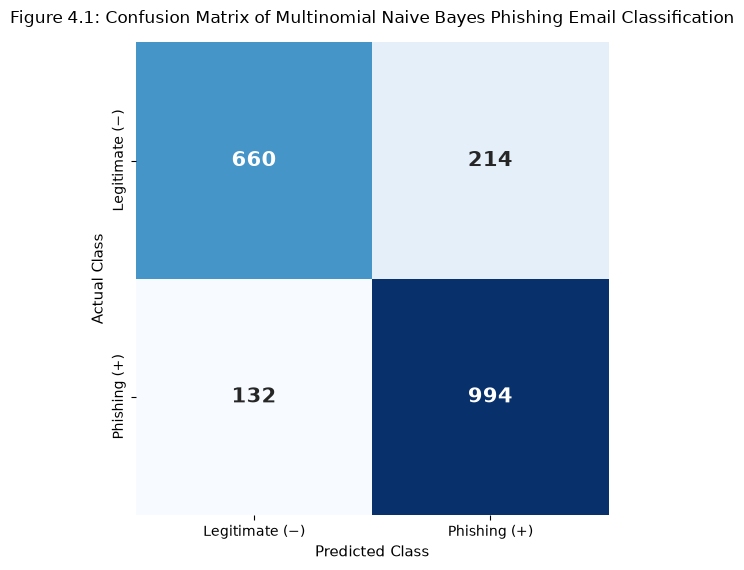

In [17]:
# SECTION B: FULL VALIDATION SET EVALUATION
from sklearn.metrics import confusion_matrix

y_full_true = np.asarray(y_val).reshape(-1)
y_full_pred = np.asarray(y_val_pred).reshape(-1)

if len(y_full_true) != len(y_full_pred):
    raise ValueError("y_val and y_val_pred must contain the same number of observations.")

# labels=[0, 1] fixes the order as Legitimate, Phishing.
full_cm = confusion_matrix(y_full_true, y_full_pred, labels=[0, 1])
full_tn, full_fp, full_fn, full_tp = full_cm.ravel()
full_total = len(y_full_true)

full_accuracy = safe_divide(full_tp + full_tn, full_total)
full_precision = safe_divide(full_tp, full_tp + full_fp)
full_recall = safe_divide(full_tp, full_tp + full_fn)
full_specificity = safe_divide(full_tn, full_tn + full_fp)
full_f1 = safe_divide(2 * full_precision * full_recall, full_precision + full_recall)

overall_rows = [
    ("Validation sample size", f"{full_total:,}"),
    ("True Positive (TP)", f"{full_tp:,}"),
    ("True Negative (TN)", f"{full_tn:,}"),
    ("False Positive (FP)", f"{full_fp:,}"),
    ("False Negative (FN)", f"{full_fn:,}"),
    ("Accuracy", f"{full_accuracy:.2%}"),
    ("Precision", f"{full_precision:.2%}"),
    ("Recall (Sensitivity)", f"{full_recall:.2%}"),
    ("Specificity", f"{full_specificity:.2%}"),
    ("F1-Score", f"{full_f1:.2%}")
]
overall_table_rows = "".join(
    f"<tr><td>{escape(label)}</td><td>{escape(value)}</td></tr>"
    for label, value in overall_rows
)
overall_html = f"""
<style>
.overall-performance {{font-family:Arial,Helvetica,sans-serif;max-width:760px;background:#fff;
 border:1px solid #d9e0e8;border-radius:10px;padding:18px;color:#1f2937;}}
.overall-performance h3 {{color:#17365d;margin:0 0 5px;font-size:20px;}}
.overall-performance p {{color:#667085;font-size:12px;margin:0 0 13px;}}
.overall-performance table {{border-collapse:collapse;width:100%;font-size:13px;}}
.overall-performance th {{background:#17365d;color:#fff;padding:9px;text-align:left;}}
.overall-performance td {{border-bottom:1px solid #e4e9ef;padding:8px 10px;}}
.overall-performance tr:nth-child(even) {{background:#f7f9fc;}}
.overall-performance td:last-child {{font-weight:700;text-align:right;color:#17365d;}}
</style>
<div class="overall-performance">
 <h3>Overall Validation Performance</h3>
 <p>Calculated from all {full_total:,} observations in the validation set.</p>
 <table><thead><tr><th>Measure</th><th style="text-align:right">Value</th></tr></thead>
 <tbody>{overall_table_rows}</tbody></table>
</div>
"""
display(HTML(overall_html))

# Standard full-validation confusion matrix figure.
fig, ax = plt.subplots(figsize=(7.2, 5.8))
sns.heatmap(
    full_cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
    xticklabels=["Legitimate (−)", "Phishing (+)"],
    yticklabels=["Legitimate (−)", "Phishing (+)"],
    annot_kws={"size": 15, "weight": "bold"}, ax=ax
)
ax.set_xlabel("Predicted Class", fontsize=11)
ax.set_ylabel("Actual Class", fontsize=11)
ax.set_title("Figure 4.1: Confusion Matrix of Multinomial Naive Bayes Phishing Email Classification",
             fontsize=12, pad=14)
plt.tight_layout()
plt.savefig("confusion_matrix_full_mnb.png", dpi=300, bbox_inches="tight")
plt.show()

# Programmatic integrity checks for the full validation evaluation.
assert full_total == len(y_val) == len(y_val_pred)
assert full_tp + full_tn + full_fp + full_fn == full_total
assert np.isclose(full_accuracy, safe_divide(full_tp + full_tn, full_total))
assert np.isclose(full_precision, safe_divide(full_tp, full_tp + full_fp))
assert np.isclose(full_recall, safe_divide(full_tp, full_tp + full_fn))
assert np.isclose(full_specificity, safe_divide(full_tn, full_tn + full_fp))
assert np.isclose(full_f1, safe_divide(2 * full_precision * full_recall,
                                      full_precision + full_recall))


In [18]:
# ============================================
# CELL 18: SAVE MODEL AND FINAL PROJECT SUMMARY
# ============================================

print("\n" + "=" * 80)
print("SAVING MODEL")
print("=" * 80)

joblib.dump(model, 'phishing_model_mnb.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer_mnb.pkl')
print("Model saved as 'phishing_model_mnb.pkl'")
print("Vectorizer saved as 'tfidf_vectorizer_mnb.pkl'")

print("\n" + "=" * 80)
print("PROJECT COMPLETE!")
print("=" * 80)

print("\nFINAL PROJECT SUMMARY:")
print("   Multinomial Naive Bayes Classifier")
print("   Single 80/20 split (No Cross-Validation)")
print("   Separate splitting per class (Phishing & Legitimate)")
print("   Training time recorded")
print("   Classification report")
print("   Confusion matrix")
print("   TP/TN/FP/FN evaluation")
print("   Class-Based Feature Probability Analysis")
print(f"   {leakage_status}")
print("   Model saved successfully")



SAVING MODEL
Model saved as 'phishing_model_mnb.pkl'
Vectorizer saved as 'tfidf_vectorizer_mnb.pkl'

PROJECT COMPLETE!

FINAL PROJECT SUMMARY:
   Multinomial Naive Bayes Classifier
   Single 80/20 split (No Cross-Validation)
   Separate splitting per class (Phishing & Legitimate)
   Training time recorded
   Classification report
   Confusion matrix
   TP/TN/FP/FN evaluation
   Class-Based Feature Probability Analysis
   Duplicates detected between training and validation sets
   Model saved successfully
